In [1]:
import pandas as pd
import numpy as np
from astropy.table import Table
from astropy.coordinates import SkyCoord
import astropy.units as u

# 1. Load your existing OHM and non-OHM targets
# (Swap these filenames if you are using 'zhang_tab_4_6.csv' etc.)
ohm_df = pd.read_csv('ohm_targets.csv', delimiter=',') 
non_ohm_df = pd.read_csv('non_ohm_targets.csv', delimiter=',')

# 2. Add the labels BEFORE combining (Crucial for the ML step!)
ohm_df['is_OHM'] = 1
non_ohm_df['is_OHM'] = 0

# Combine into one master target DataFrame
targets_df = pd.concat([ohm_df, non_ohm_df], ignore_index=True)

# 3. Load the AKARI FIS Catalogue
print("Loading AKARI FIS Catalogue...")
akari_table = Table.read("fis.dat", format="ascii.cds", readme="ReadMe.txt")

# 4. Set up SkyCoords
# (Ensure 'RAJ2000' and 'DEJ2000' match your CSV column names exactly)
target_coords = SkyCoord(ra=targets_df['RAJ2000'], dec=targets_df['DEJ2000'], unit=(u.hourangle, u.deg), frame='icrs')
akari_coords = SkyCoord(ra=akari_table['RAdeg'], dec=akari_table['DEdeg'], unit=(u.deg, u.deg), frame='icrs')

# 5. KD-Tree Cross-Match
print("Running KD-Tree cross-match...")
idx, d2d, d3d = target_coords.match_to_catalog_sky(akari_coords)

# 6. Enforce 10-arcsecond search radius
max_sep = 10.0 * u.arcsec
match_mask = d2d < max_sep

print(f"Total successful AKARI matches: {match_mask.sum()} out of {len(targets_df)} targets")

# 7. Extract matches and merge Far-IR Data
# Convert the matched AKARI rows into a Pandas DataFrame
matched_akari_data = akari_table[idx].to_pandas()

# Create new columns for the AKARI fluxes, filling with NaN if the galaxy wasn't a match
targets_df['S65'] = np.where(match_mask, matched_akari_data['S65'], np.nan)
targets_df['S90'] = np.where(match_mask, matched_akari_data['S90'], np.nan)
targets_df['S140'] = np.where(match_mask, matched_akari_data['S140'], np.nan)
targets_df['S160'] = np.where(match_mask, matched_akari_data['S160'], np.nan)

print("Cross-match complete! FIR fluxes appended.")

Loading AKARI FIS Catalogue...
Running KD-Tree cross-match...
Total successful AKARI matches: 277 out of 386 targets
Cross-match complete! FIR fluxes appended.


In [2]:
targets_df

,IRAS,n_IRAS,r_IRAS,RAJ2000,DEJ2000,Dr,W1,e_W1,l_W2,W2,...,Dec_str,OH_Line_Flux_Jy_km_s,RA_deg,Dec_deg,Peak_Flux_mJy,z_OH,S65,S90,S140,S160
0,00057+4021,NaN,c,00 08 20.44,+40 37 56.0,1.555,12.369,0.023,NaN,12.209,...,NaN,NaN,NaN,NaN,NaN,NaN,4.0420,3.8930,3.449,3.9850
1,00335-2732,NaN,c,00 36 00.37,-27 15 33.8,0.109,12.376,0.024,NaN,11.228,...,NaN,NaN,NaN,NaN,NaN,NaN,3.7000,2.9170,1.763,0.6372
2,00450-2533,*,c,00 47 33.07,-25 17 19.0,1.609,5.865,0.032,NaN,5.264,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,00461-0728,NaN,a,00 48 39.50,-07 12 21.0,0.239,15.129,0.044,NaN,14.136,...,NaN,NaN,NaN,NaN,NaN,NaN,0.8190,0.6780,1.788,1.0560
4,00509+1225,NaN,c,00 53 34.92,+12 41 35.9,0.201,8.862,0.024,NaN,7.802,...,NaN,NaN,NaN,NaN,NaN,NaN,1.6060,1.9640,2.575,3.0550
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
381,23327+2913,NaN,NaN,23 35 11.90,+29 30 00.0,0.446,12.838,0.024,NaN,11.979,...,NaN,NaN,NaN,NaN,NaN,NaN,1.6200,1.7400,2.178,1.9970
382,23444+0441,NaN,NaN,23 46 59.60,+04 57 57.0,6.678,12.916,0.026,NaN,12.164,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
383,23498+2423,NaN,NaN,23 52 26.00,+24 40 17.0,0.977,11.508,0.022,NaN,10.363,...,NaN,NaN,NaN,NaN,NaN,NaN,0.9649,0.9977,2.611,1.4600
384,23539+2322,NaN,NaN,23 56 30.70,+23 38 51.0,7.642,13.466,0.027,NaN,11.354,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [3]:
from sklearn.preprocessing import StandardScaler

# 1. Engineer the color indices (if they aren't already in your CSV)
targets_df['W1-W2'] = targets_df['W1'] - targets_df['W2']
targets_df['W2-W3'] = targets_df['W2'] - targets_df['W3']
targets_df['W3-W4'] = targets_df['W3'] - targets_df['W4']

# 2. Define the Master Feature List
# Note: Ensure the 'alf' and 'logL' names match your exact columns perfectly!
master_columns = [
    'W1', 'W2', 'W3', 'W4',                      # Mid-IR Magnitudes
    'W1-W2', 'W2-W3', 'W3-W4',                   # Mid-IR Colors
    'alf21', 'alf32', 'alf43', 'alf41',          # Spectral Indices
    'logLW1', 'logLW2', 'logLW3', 'logLW4',      # Luminosities
    'S65', 'S90', 'S140'                         # AKARI Far-IR Fluxes (Dropping S160 if heavily missing, or add it in)
]

# 3. Clean Missing Data (NaNs will instantly crash Scikit-Learn)
clean_data = targets_df.dropna(subset=master_columns + ['is_OHM']).copy()

# 4. Set up Features (X) and Labels (y)
X = clean_data[master_columns].values.astype(float)
y = clean_data['is_OHM'].astype(int)

# 5. The Golden Rule: Standardize the Master Feature Matrix
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print(f"Master Feature Matrix built and standardized!")
print(f"Shape: {X_scaled.shape} (Galaxies, Features)")
print(f"Total OHMs ready for ML: {sum(y == 1)}")
print(f"Total Non-OHMs ready for ML: {sum(y == 0)}")

Master Feature Matrix built and standardized!
Shape: (259, 18) (Galaxies, Features)
Total OHMs ready for ML: 93
Total Non-OHMs ready for ML: 166


# Unsupervised ML

Running PCA on Spectral Indices...
Running t-SNE on Spectral Indices...


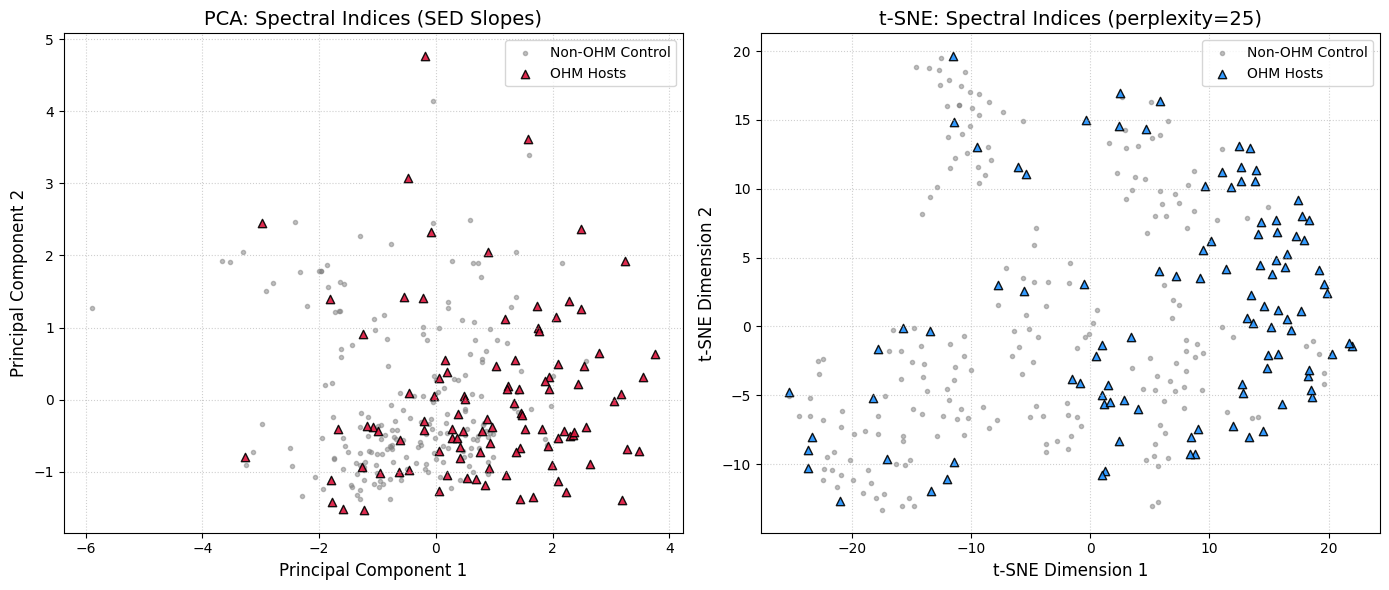

PCA Component 1 explains 53.88% of the variance.
PCA Component 2 explains 28.96% of the variance.


In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE

# 1. Isolate the spectral index columns
spectral_cols = ['alf21', 'alf32', 'alf43', 'alf41']

# 2. Targeted Data Cleaning
# We drop rows missing ANY of the spectral indices to prevent LinAlgErrors.
# Create a fresh DataFrame so we don't accidentally shrink the main dataset.
# (Change 'targets_df' to whatever your combined dataframe is named)
clean_spec_data = targets_df.dropna(subset=spectral_cols + ['is_OHM']).copy()

# 3. Re-establish the Boolean Masks
# This ensures our labels match the exact length of our newly cleaned data
ohm_mask = clean_spec_data['is_OHM'] == 1
non_ohm_mask = clean_spec_data['is_OHM'] == 0

# 4. Extract and Standardize the Features
X_spec = clean_spec_data[spectral_cols].values.astype(float)
scaler = StandardScaler()
X_spec_scaled = scaler.fit_transform(X_spec)

# 5. Run PCA
print("Running PCA on Spectral Indices...")
pca = PCA(n_components=2)
pca_results = pca.fit_transform(X_spec_scaled)

# 6. Run t-SNE
print("Running t-SNE on Spectral Indices...")
tsne = TSNE(n_components=2, perplexity=25, random_state=42)
tsne_results = tsne.fit_transform(X_spec_scaled)

# 7. Plot the Results Side-by-Side
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# ---- Plot A: PCA ----
axes[0].scatter(pca_results[non_ohm_mask, 0], pca_results[non_ohm_mask, 1], 
                color='gray', alpha=0.5, label='Non-OHM Control', marker='.')
axes[0].scatter(pca_results[ohm_mask, 0], pca_results[ohm_mask, 1], 
                color='crimson', alpha=0.9, label='OHM Hosts', marker='^', edgecolor='black')
axes[0].set_title('PCA: Spectral Indices (SED Slopes)', fontsize=14)
axes[0].set_xlabel('Principal Component 1', fontsize=12)
axes[0].set_ylabel('Principal Component 2', fontsize=12)
axes[0].legend()
axes[0].grid(True, linestyle=':', alpha=0.6)

# ---- Plot B: t-SNE ----
axes[1].scatter(tsne_results[non_ohm_mask, 0], tsne_results[non_ohm_mask, 1], 
                color='gray', alpha=0.5, label='Non-OHM Control', marker='.')
axes[1].scatter(tsne_results[ohm_mask, 0], tsne_results[ohm_mask, 1], 
                color='dodgerblue', alpha=0.9, label='OHM Hosts', marker='^', edgecolor='black')
axes[1].set_title('t-SNE: Spectral Indices (perplexity=25)', fontsize=14)
axes[1].set_xlabel('t-SNE Dimension 1', fontsize=12)
axes[1].set_ylabel('t-SNE Dimension 2', fontsize=12)
axes[1].legend()
axes[1].grid(True, linestyle=':', alpha=0.6)

plt.tight_layout()
plt.show()

# 8. Check the PCA Variance
explained_variance = pca.explained_variance_ratio_
print(f"PCA Component 1 explains {explained_variance[0]*100:.2f}% of the variance.")
print(f"PCA Component 2 explains {explained_variance[1]*100:.2f}% of the variance.")

Running UMAP on the Master Feature Matrix...


/users/jraghoo42/hons/hons_env/lib/python3.11/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


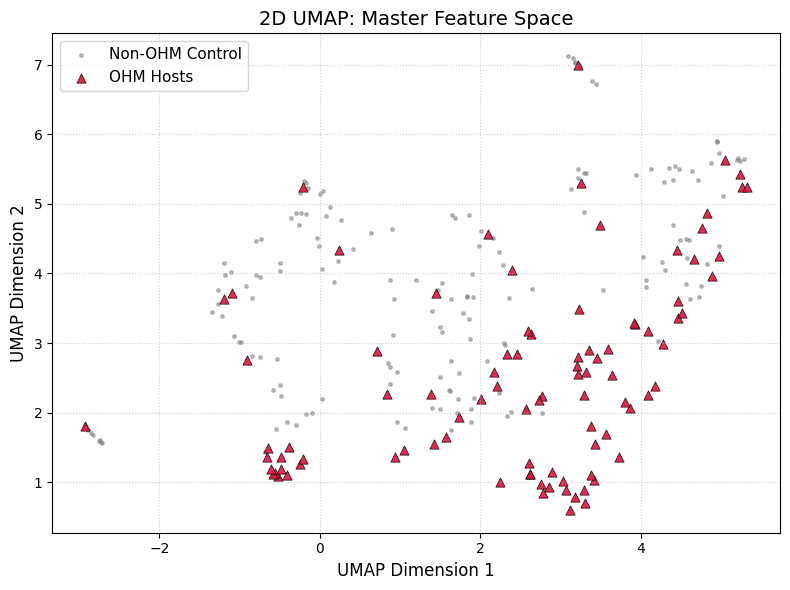

In [5]:
import matplotlib.pyplot as plt
import umap

# 1. Initialize and fit UMAP on the Master Feature Matrix (or X_spec_scaled)
print("Running UMAP on the Master Feature Matrix...")
reducer = umap.UMAP(n_neighbors=15, min_dist=0.05, n_components=2, random_state=42)
umap_results = reducer.fit_transform(X_scaled)

# 2. Boolean masks for class plotting
ohm_mask_master = (y == 1)
non_ohm_mask_master = (y == 0)

# 3. Plot 2D UMAP Projection
plt.figure(figsize=(8, 6))
plt.scatter(
    umap_results[non_ohm_mask_master, 0], 
    umap_results[non_ohm_mask_master, 1], 
    color='gray', 
    alpha=0.5, 
    s=25, 
    label='Non-OHM Control', 
    marker='.'
)
plt.scatter(
    umap_results[ohm_mask_master, 0], 
    umap_results[ohm_mask_master, 1], 
    color='crimson', 
    alpha=0.9, 
    s=45, 
    label='OHM Hosts', 
    marker='^', 
    edgecolor='black',
    linewidth=0.5
)

plt.title('2D UMAP: Master Feature Space', fontsize=14)
plt.xlabel('UMAP Dimension 1', fontsize=12)
plt.ylabel('UMAP Dimension 2', fontsize=12)
plt.legend(loc='best', fontsize=11)
plt.grid(True, linestyle=':', alpha=0.6)
plt.tight_layout()
plt.show()

# Supervised ML
## RFC, F scores, ROC etc.

--- Default Model Metrics (Threshold = 0.50) ---
Recall:   0.526
F1 Score: 0.606
F2 Score: 0.556
ROC AUC:  0.860

--- Optimized Metrics (Threshold = 0.20) ---
Maximized F2 Score: 0.857
Recall at Best Cut: 0.947


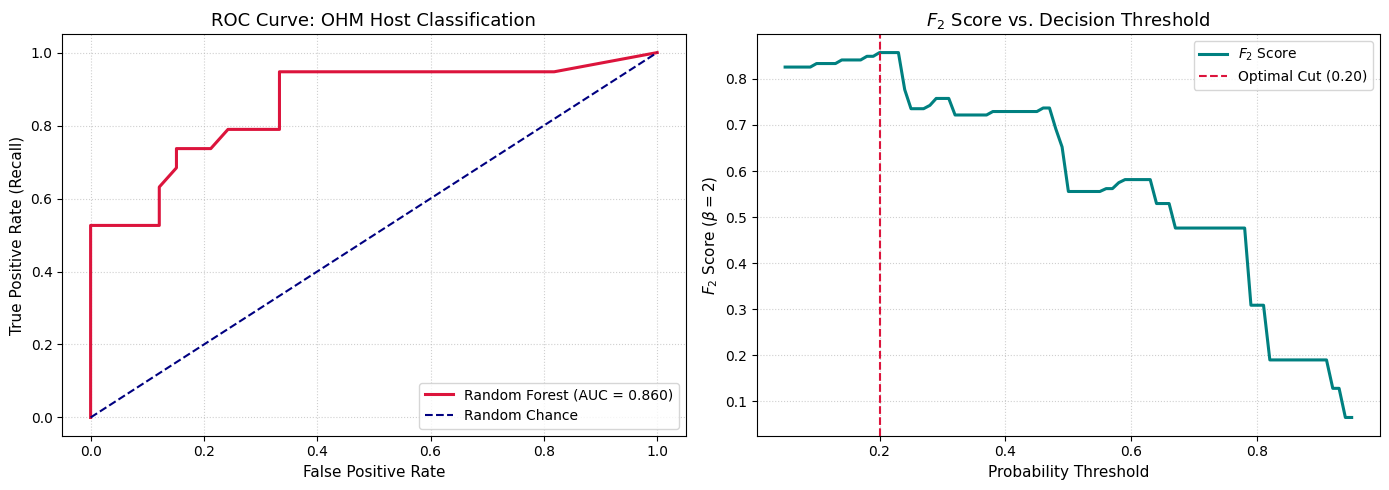

In [6]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    classification_report,
    f1_score,
    fbeta_score,
    recall_score,
    roc_auc_score,
    roc_curve,
)

# 1. 80-20 Stratified Train/Test Split
X_train, X_test, y_train, y_test = train_test_split(
    X_scaled, y, test_size=0.2, random_state=42, stratify=y
)

# 2. Fit Random Forest Classifier
rf_model = RandomForestClassifier(n_estimators=100, random_state=42, class_weight='balanced')
rf_model.fit(X_train, y_train)

# 3. Predict Probabilities and Default Classes (Threshold = 0.50)
y_probs = rf_model.predict_proba(X_test)[:, 1]
y_pred_default = (y_probs >= 0.50).astype(int)

# 4. Standard Metrics
rec_default = recall_score(y_test, y_pred_default)
f1_default = f1_score(y_test, y_pred_default)
f2_default = fbeta_score(y_test, y_pred_default, beta=2)
auc_score = roc_auc_score(y_test, y_probs)

print("--- Default Model Metrics (Threshold = 0.50) ---")
print(f"Recall:   {rec_default:.3f}")
print(f"F1 Score: {f1_default:.3f}")
print(f"F2 Score: {f2_default:.3f}")
print(f"ROC AUC:  {auc_score:.3f}")

# 5. Threshold Optimization for F2 Score
thresholds = np.linspace(0.05, 0.95, 91)
f2_curve = [fbeta_score(y_test, (y_probs >= t).astype(int), beta=2) for t in thresholds]
best_idx = np.argmax(f2_curve)
best_t = thresholds[best_idx]
best_f2 = f2_curve[best_idx]
best_rec = recall_score(y_test, (y_probs >= best_t).astype(int))

print(f"\n--- Optimized Metrics (Threshold = {best_t:.2f}) ---")
print(f"Maximized F2 Score: {best_f2:.3f}")
print(f"Recall at Best Cut: {best_rec:.3f}")

# 6. Plot ROC Curve and F2 vs Threshold Side-by-Side
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# ROC Curve
fpr, tpr, _ = roc_curve(y_test, y_probs)
axes[0].plot(fpr, tpr, color='crimson', lw=2.2, label=f'Random Forest (AUC = {auc_score:.3f})')
axes[0].plot([0, 1], [0, 1], color='navy', linestyle='--', lw=1.5, label='Random Chance')
axes[0].set_title('ROC Curve: OHM Host Classification', fontsize=13)
axes[0].set_xlabel('False Positive Rate', fontsize=11)
axes[0].set_ylabel('True Positive Rate (Recall)', fontsize=11)
axes[0].legend(loc='lower right', fontsize=10)
axes[0].grid(True, linestyle=':', alpha=0.6)

# F2 vs Threshold Curve
axes[1].plot(thresholds, f2_curve, color='teal', lw=2.2, label=r'$F_2$ Score')
axes[1].axvline(best_t, color='crimson', linestyle='--', label=f'Optimal Cut ({best_t:.2f})')
axes[1].set_title(r'$F_2$ Score vs. Decision Threshold', fontsize=13)
axes[1].set_xlabel('Probability Threshold', fontsize=11)
axes[1].set_ylabel(r'$F_2$ Score ($\beta=2$)', fontsize=11)
axes[1].legend(loc='best', fontsize=10)
axes[1].grid(True, linestyle=':', alpha=0.6)

plt.tight_layout()
plt.show()

## stratified 5 fold cross-validation and feature importances

In [10]:
# 1. Force y into a NumPy array to drop the fragmented Pandas index
y_array = y.values if isinstance(y, pd.Series) else y

print("--- Running Stratified 5-Fold Cross-Validation ---")
# Pass the newly stripped y_array into the split
for fold, (train_idx, val_idx) in enumerate(skf.split(X, y_array), 1):
    X_tr, X_val = X[train_idx], X[val_idx]
    
    # 2. Extract y using the new NumPy array
    y_tr, y_val = y_array[train_idx], y_array[val_idx]
    
    # Scale within each fold to prevent data leakage
    s = StandardScaler()
    X_tr_s = s.fit_transform(X_tr)
    X_val_s = s.transform(X_val)
    
    # Train Random Forest
    rf_cv = RandomForestClassifier(n_estimators=100, random_state=42, class_weight='balanced')
    rf_cv.fit(X_tr_s, y_tr)
    
    preds_val = rf_cv.predict(X_val_s)
    fold_importances.append(rf_cv.feature_importances_)
    fold_f1_scores.append(f1_score(y_val, preds_val))
    fold_f2_scores.append(fbeta_score(y_val, preds_val, beta=2))
    
    print(f"Fold {fold}: F1 = {fold_f1_scores[-1]:.3f} | F2 = {fold_f2_scores[-1]:.3f}")

--- Running Stratified 5-Fold Cross-Validation ---
Fold 1: F1 = 0.824 | F2 = 0.745
Fold 2: F1 = 0.900 | F2 = 0.900
Fold 3: F1 = 0.857 | F2 = 0.882
Fold 4: F1 = 0.737 | F2 = 0.761
Fold 5: F1 = 1.000 | F2 = 1.000
Fold 6: F1 = 0.750 | F2 = 0.698
Fold 7: F1 = 0.889 | F2 = 0.889
Fold 8: F1 = 0.824 | F2 = 0.795
Fold 9: F1 = 0.842 | F2 = 0.870
Fold 10: F1 = 0.533 | F2 = 0.476


In [13]:
# Force BOTH X and y into raw NumPy arrays to strip the fragmented Pandas indices
X_array = X.values if hasattr(X, 'values') else X
y_array = y.values if hasattr(y, 'values') else y

print("--- Running Stratified 5-Fold Cross-Validation ---")
for fold, (train_idx, val_idx) in enumerate(skf.split(X_array, y_array), 1):
    # Now indexing by raw integer positions will work perfectly
    X_tr, X_val = X_array[train_idx], X_array[val_idx]
    y_tr, y_val = y_array[train_idx], y_array[val_idx]
    
    # Scale within each fold to prevent data leakage
    s = StandardScaler()
    X_tr_s = s.fit_transform(X_tr)
    X_val_s = s.transform(X_val)
    
    # Train Random Forest
    rf_cv = RandomForestClassifier(n_estimators=100, random_state=42, class_weight='balanced')
    rf_cv.fit(X_tr_s, y_tr)
    
    preds_val = rf_cv.predict(X_val_s)
    fold_importances.append(rf_cv.feature_importances_)
    fold_f1_scores.append(f1_score(y_val, preds_val))
    fold_f2_scores.append(fbeta_score(y_val, preds_val, beta=2))
    
    print(f"Fold {fold}: F1 = {fold_f1_scores[-1]:.3f} | F2 = {fold_f2_scores[-1]:.3f}")

--- Running Stratified 5-Fold Cross-Validation ---
Fold 1: F1 = 0.824 | F2 = 0.745
Fold 2: F1 = 0.900 | F2 = 0.900
Fold 3: F1 = 0.857 | F2 = 0.882
Fold 4: F1 = 0.737 | F2 = 0.761
Fold 5: F1 = 1.000 | F2 = 1.000
Fold 6: F1 = 0.750 | F2 = 0.698
Fold 7: F1 = 0.889 | F2 = 0.889
Fold 8: F1 = 0.824 | F2 = 0.795
Fold 9: F1 = 0.842 | F2 = 0.870
Fold 10: F1 = 0.533 | F2 = 0.476


Task was destroyed but it is pending!
task: <Task pending name='Task-3173' coro=<_async_in_context.<locals>.run_in_context() done, defined at /users/jraghoo42/hons/hons_env/lib/python3.11/site-packages/ipykernel/utils.py:57> wait_for=<Task pending name='Task-3174' coro=<Kernel.shell_main() running at /users/jraghoo42/hons/hons_env/lib/python3.11/site-packages/ipykernel/kernelbase.py:597> cb=[Task.task_wakeup()]> cb=[ZMQStream._run_callback.<locals>._log_error() at /users/jraghoo42/hons/hons_env/lib/python3.11/site-packages/zmq/eventloop/zmqstream.py:563]>
/software/common/python/3.11.11/lib/python3.11/tokenize.py:529: RuntimeWarning: coroutine 'Kernel.shell_main' was never awaited
  pseudomatch = _compile(PseudoToken).match(line, pos)
Task was destroyed but it is pending!
task: <Task pending name='Task-3174' coro=<Kernel.shell_main() running at /users/jraghoo42/hons/hons_env/lib/python3.11/site-packages/ipykernel/kernelbase.py:597> cb=[Task.task_wakeup()]>
Task was destroyed but it is 

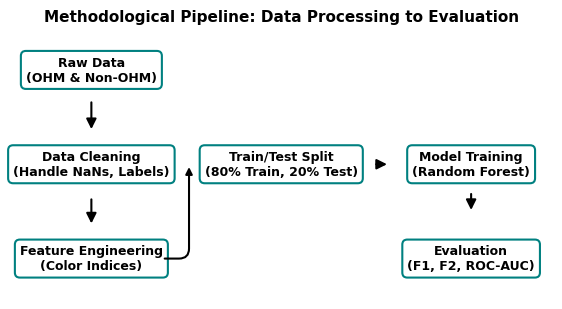

In [17]:
import matplotlib.pyplot as plt

# 1. Reduce figsize to cut down white space and make the diagram compact
fig, ax = plt.subplots(figsize=(7, 3.5))

# Lock the axis limits so Matplotlib doesn't add invisible padding
ax.set_xlim(0, 1)
ax.set_ylim(0, 1)
ax.axis('off')

# Define tighter box and arrow properties
box_props = dict(boxstyle="round,pad=0.4", fc="white", ec="teal", lw=1.5)
arrow_props = dict(arrowstyle='-|>', color='black', lw=1.5, mutation_scale=15)

# 2. Compact positioning mapping
stages = {
    "Raw": ("Raw Data\n(OHM & Non-OHM)", (0.15, 0.85)),
    "Clean": ("Data Cleaning\n(Handle NaNs, Labels)", (0.15, 0.5)),
    "Feat": ("Feature Engineering\n(Color Indices)", (0.15, 0.15)),
    "Split": ("Train/Test Split\n(80% Train, 20% Test)", (0.5, 0.5)),
    "Model": ("Model Training\n(Random Forest)", (0.85, 0.5)),
    "Eval": ("Evaluation\n(F1, F2, ROC-AUC)", (0.85, 0.15))
}

# Draw boxes
for key, (text, pos) in stages.items():
    ax.text(pos[0], pos[1], text, ha="center", va="center", size=9, weight='bold', bbox=box_props)

# 3. Draw clean, direct arrows
ax.annotate("", xy=(0.15, 0.62), xytext=(0.15, 0.74), arrowprops=arrow_props) # Raw -> Clean
ax.annotate("", xy=(0.15, 0.27), xytext=(0.15, 0.38), arrowprops=arrow_props) # Clean -> Feature

# Feature -> Split (Elbow arrow)
ax.annotate("", xy=(0.33, 0.5), xytext=(0.28, 0.15), 
            arrowprops=dict(arrowstyle='-|>', color='black', lw=1.5, connectionstyle="angle,angleA=0,angleB=90,rad=10"))

# Split -> Model
ax.annotate("", xy=(0.7, 0.5), xytext=(0.67, 0.5), arrowprops=arrow_props)

# Model -> Eval
ax.annotate("", xy=(0.85, 0.32), xytext=(0.85, 0.40), arrowprops=arrow_props)

plt.title("Methodological Pipeline: Data Processing to Evaluation", fontsize=11, weight='bold')

plt.savefig('pipeline.png', dpi=300, bbox_inches='tight')


plt.show()

--- Running Stratified 5-Fold Cross-Validation ---
Fold 1: F1 = 0.882 | F2 = 0.824
Fold 2: F1 = 0.789 | F2 = 0.789
Fold 3: F1 = 0.889 | F2 = 0.860
Fold 4: F1 = 0.857 | F2 = 0.843
Fold 5: F1 = 0.667 | F2 = 0.632

Mean 5-Fold F1 Score: 0.817 (±0.083)
Mean 5-Fold F2 Score: 0.790 (±0.082)


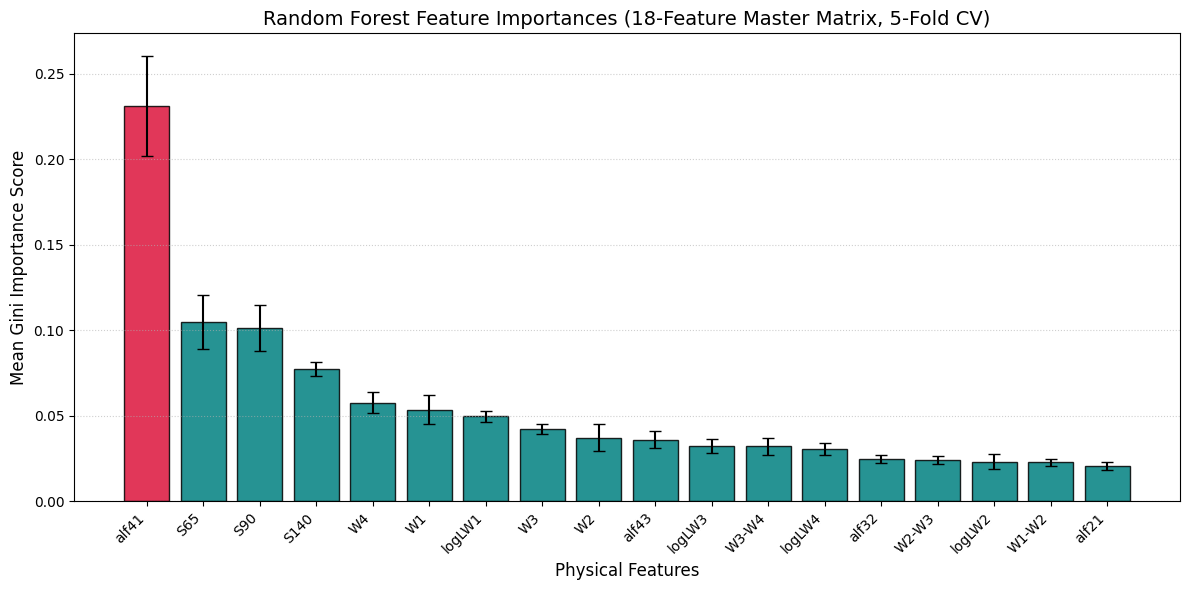

In [8]:
from sklearn.model_selection import StratifiedKFold
import numpy as np

# 1. Force y into a NumPy array to drop the fragmented Pandas index
y_array = y.values if isinstance(y, pd.Series) else y

# 2. Initialize Stratified 5-Fold Split
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

fold_importances = []
fold_f1_scores = []
fold_f2_scores = []

print("--- Running Stratified 5-Fold Cross-Validation ---")
# Pass the newly stripped y_array into the split
for fold, (train_idx, val_idx) in enumerate(skf.split(X, y_array), 1):
    X_tr, X_val = X[train_idx], X[val_idx]
    y_tr, y_val = y_array[train_idx], y_array[val_idx]
    
    # Scale within each fold to prevent data leakage
    s = StandardScaler()
    X_tr_s = s.fit_transform(X_tr)
    X_val_s = s.transform(X_val)
    
    # Train Random Forest
    rf_cv = RandomForestClassifier(n_estimators=100, random_state=42, class_weight='balanced')
    rf_cv.fit(X_tr_s, y_tr)
    
    preds_val = rf_cv.predict(X_val_s)
    
    # Track metrics and feature importances
    fold_importances.append(rf_cv.feature_importances_)
    fold_f1_scores.append(f1_score(y_val, preds_val))
    fold_f2_scores.append(fbeta_score(y_val, preds_val, beta=2))
    
    print(f"Fold {fold}: F1 = {fold_f1_scores[-1]:.3f} | F2 = {fold_f2_scores[-1]:.3f}")

# 3. Compute Mean and Standard Deviation of Feature Importances
mean_imp = np.mean(fold_importances, axis=0)
std_imp = np.std(fold_importances, axis=0)

print(f"\nMean 5-Fold F1 Score: {np.mean(fold_f1_scores):.3f} (±{np.std(fold_f1_scores):.3f})")
print(f"Mean 5-Fold F2 Score: {np.mean(fold_f2_scores):.3f} (±{np.std(fold_f2_scores):.3f})")

# 4. Plot Sorted Feature Importance Bar Chart
sorted_idx = np.argsort(mean_imp)[::-1]
sorted_feats = [master_columns[i] for i in sorted_idx]
sorted_means = mean_imp[sorted_idx]
sorted_stds = std_imp[sorted_idx]

plt.figure(figsize=(12, 6))
bars = plt.bar(
    sorted_feats, 
    sorted_means, 
    yerr=sorted_stds, 
    capsize=4, 
    color='teal', 
    edgecolor='black', 
    alpha=0.85
)

# Highlight top-ranked feature
bars[0].set_color('crimson')
bars[0].set_edgecolor('black')

plt.title('Random Forest Feature Importances (18-Feature Master Matrix, 5-Fold CV)', fontsize=14)
plt.ylabel('Mean Gini Importance Score', fontsize=12)
plt.xlabel('Physical Features', fontsize=12)
plt.xticks(rotation=45, ha='right')
plt.grid(axis='y', linestyle=':', alpha=0.6)
plt.tight_layout()
plt.show()